# 1. Project Overview


This project investigates how AI and forecasting methods can support food preparation and ordering decisions in commercial kitchens through natural-language questions.

The research compares selected forecasting and Machine Learning models using historical sales data to determine which methods provide the most accurate demand predictions. The selected model is then combined with recipe and ingredient data, as well as simulated stock, to generate preparation and ordering recommendations.

The Proof of Concept uses these results to produce preparation and ordering recommendations that kitchen staff can access through natural-language questions.

The sales and ingredient data used in this project were obtained from the *Dominoes-TimeseriesForecasting* repository (Kondur, n.d.).

## Reference

Kondur, P. (n.d.). *Dominoes-TimeseriesForecasting* [Data set]. GitHub. https://github.com/pramodkondur/Dominoes-TimeseriesForecasting


# 2. Importing Libraries

The first step of the analytical workflow is to import the Python libraries required for data preparation and exploratory analysis. Pandas is used to work with structured datasets, while NumPy supports numerical operations required during data transformation.

Visualisation libraries such as Matplotlib and Seaborn are included to explore the data and identify patterns or unusual values before developing and comparing the forecasting models.

Additional Machine Learning libraries will be introduced later in the notebook when the forecasting stage is implemented.

### References

Pandas Development Team. (n.d.). *Pandas user guide*. https://pandas.pydata.org/docs/

Harris, C. R., et al. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 3. Loading the Dataset

The data used in this project are obtained from the *Dominoes-TimeseriesForecasting* repository. The repository provides historical pizza sales and recipe information, together with cleaned and time-series versions created by the original author.

Five files are available for this project. `Pizza_Sale.xlsx` contains the original sales records, while `Pizza_ingredients.xlsx` contains the ingredients and quantities required for each pizza. The remaining three files contain cleaned or transformed versions produced by the original project.

For this analysis, the two original files are used as the starting point. 
### Reference

Kondur, P. (n.d.). *Dominoes-TimeseriesForecasting* [Data set]. GitHub. https://github.com/pramodkondur/Dominoes-TimeseriesForecasting

In [2]:

sales = pd.read_excel("DataSet/1.Pizza_Sale.xlsx")
ingredients = pd.read_excel("DataSet/2.Pizza_ingredients.xlsx")

print("Sales dataset loaded:", sales.shape)
print("Ingredients dataset loaded:", ingredients.shape)

Sales dataset loaded: (48620, 12)
Ingredients dataset loaded: (518, 4)


# 4. Initial Data Inspection

Before preprocessing the data, the structure and content of both datasets are inspected. This includes the column names, data types and a sample of the records.

In [3]:
print("SALES DATASET")
display(sales.head())

print("\nSales data types:")
display(sales.dtypes)

print("\nINGREDIENTS DATASET")
display(ingredients.head())

print("\nIngredients data types:")
display(ingredients.dtypes)

SALES DATASET


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,2015-01-01 00:00:00,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,2015-01-01 00:00:00,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,2015-01-01 00:00:00,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,2015-01-01 00:00:00,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,2015-01-01 00:00:00,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza



Sales data types:


pizza_id               int64
order_id               int64
pizza_name_id         object
quantity               int64
order_date            object
order_time            object
unit_price           float64
total_price          float64
pizza_size            object
pizza_category        object
pizza_ingredients     object
pizza_name            object
dtype: object


INGREDIENTS DATASET


,pizza_name_id,pizza_name,pizza_ingredients,Items_Qty_In_Grams
0,bbq_ckn_l,The Barbecue Chicken Pizza,Barbecued Chicken,40.0
1,bbq_ckn_l,The Barbecue Chicken Pizza,Red Peppers,15.0
2,bbq_ckn_l,The Barbecue Chicken Pizza,Green Peppers,20.0
3,bbq_ckn_l,The Barbecue Chicken Pizza,Tomatoes,30.0
4,bbq_ckn_l,The Barbecue Chicken Pizza,Red Onions,60.0



Ingredients data types:


pizza_name_id          object
pizza_name             object
pizza_ingredients      object
Items_Qty_In_Grams    float64
dtype: object

# 5. Data Quality Assessment

The two datasets are checked for missing values, duplicates and other data quality issues before preprocessing.

In [4]:
print("Missing values in sales:")
display(sales.isnull().sum())

print("\nMissing values in ingredients:")
display(ingredients.isnull().sum())

Missing values in sales:


pizza_id              0
order_id              0
pizza_name_id        16
quantity              0
order_date            0
order_time            0
unit_price            0
total_price           7
pizza_size            0
pizza_category       23
pizza_ingredients    13
pizza_name            7
dtype: int64


Missing values in ingredients:


pizza_name_id         0
pizza_name            0
pizza_ingredients     0
Items_Qty_In_Grams    4
dtype: int64

## 5.1 Missing Values in Sales Data

The sales dataset contains missing values in five columns. The affected records are inspected before deciding how they should be treated.

In [5]:
sales_missing = sales[sales.isnull().any(axis=1)]

print("Sales rows containing missing values:", len(sales_missing))
display(sales_missing)

Sales rows containing missing values: 66


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
36,37,15,NaN,1,2015-01-01 00:00:00,13:33:00,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
37,38,15,NaN,1,2015-01-01 00:00:00,13:33:00,20.75,20.75,L,Supreme,"Soppressata Salami, Fontina Cheese, Mozzarella...",The Soppressata Pizza
38,39,15,NaN,1,2015-01-01 00:00:00,13:33:00,12.00,12.00,S,Classic,"Kalamata Olives, Feta Cheese, Tomatoes, Garlic...",The Greek Pizza
39,40,16,NaN,1,2015-01-01 00:00:00,13:34:07,17.95,17.95,L,Veggie,"Ricotta Cheese, Gorgonzola Piccante Cheese, Mo...",The Four Cheese Pizza
40,41,16,NaN,1,2015-01-01 00:00:00,13:34:07,12.00,12.00,S,Classic,"Tomatoes, Anchovies, Green Olives, Red Onions,...",The Napolitana Pizza
...,...,...,...,...,...,...,...,...,...,...,...,...
783,784,342,sicilian_l,1,2015-06-01 00:00:00,15:44:12,20.25,NaN,L,Supreme,"Coarse Sicilian Salami, Tomatoes, Green Olives...",The Sicilian Pizza
784,785,342,southw_ckn_l,1,2015-06-01 00:00:00,15:44:12,20.75,NaN,L,Chicken,"Chicken, Tomatoes, Red Peppers, Red Onions, Ja...",The Southwest Chicken Pizza
785,786,343,five_cheese_l,1,2015-06-01 00:00:00,15:45:37,18.50,NaN,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
786,787,343,four_cheese_m,1,2015-06-01 00:00:00,15:45:37,14.75,NaN,M,Veggie,"Ricotta Cheese, Gorgonzola Piccante Cheese, Mo...",The Four Cheese Pizza


The 66 affected rows are separated by column to see where each missing value occurs and what information is still available in those records.

In [6]:
missing_columns = [
    "pizza_name_id",
    "total_price",
    "pizza_category",
    "pizza_ingredients",
    "pizza_name"
]

for column in missing_columns:
    print(f"\nMissing {column}:")
    display(sales[sales[column].isnull()])


Missing pizza_name_id:


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
36,37,15,NaN,1,2015-01-01 00:00:00,13:33:00,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
37,38,15,NaN,1,2015-01-01 00:00:00,13:33:00,20.75,20.75,L,Supreme,"Soppressata Salami, Fontina Cheese, Mozzarella...",The Soppressata Pizza
38,39,15,NaN,1,2015-01-01 00:00:00,13:33:00,12.00,12.00,S,Classic,"Kalamata Olives, Feta Cheese, Tomatoes, Garlic...",The Greek Pizza
39,40,16,NaN,1,2015-01-01 00:00:00,13:34:07,17.95,17.95,L,Veggie,"Ricotta Cheese, Gorgonzola Piccante Cheese, Mo...",The Four Cheese Pizza
40,41,16,NaN,1,2015-01-01 00:00:00,13:34:07,12.00,12.00,S,Classic,"Tomatoes, Anchovies, Green Olives, Red Onions,...",The Napolitana Pizza
41,42,16,NaN,1,2015-01-01 00:00:00,13:34:07,20.75,20.75,L,Chicken,"Chicken, Pineapple, Tomatoes, Red Peppers, Tha...",The Thai Chicken Pizza
309,310,131,NaN,1,2015-02-01 00:00:00,21:33:10,12.00,12.00,S,Veggie,"Spinach, Mushrooms, Tomatoes, Green Olives, Fe...",The Green Garden Pizza
310,311,131,NaN,1,2015-02-01 00:00:00,21:33:10,12.50,12.50,S,Supreme,"Spinach, Red Onions, Pepperoni, Tomatoes, Arti...",The Spinach Supreme Pizza
311,312,132,NaN,1,2015-02-01 00:00:00,21:42:45,9.75,9.75,S,Classic,"Mozzarella Cheese, Pepperoni",The Pepperoni Pizza
312,313,133,NaN,1,2015-02-01 00:00:00,22:00:17,20.75,20.75,L,Chicken,"Barbecued Chicken, Red Peppers, Green Peppers,...",The Barbecue Chicken Pizza



Missing total_price:


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
781,782,341,bbq_ckn_m,1,2015-06-01 00:00:00,15:35:47,16.75,NaN,M,Chicken,"Barbecued Chicken, Red Peppers, Green Peppers,...",The Barbecue Chicken Pizza
782,783,341,pepperoni_s,1,2015-06-01 00:00:00,15:35:47,9.75,NaN,S,Classic,"Mozzarella Cheese, Pepperoni",The Pepperoni Pizza
783,784,342,sicilian_l,1,2015-06-01 00:00:00,15:44:12,20.25,NaN,L,Supreme,"Coarse Sicilian Salami, Tomatoes, Green Olives...",The Sicilian Pizza
784,785,342,southw_ckn_l,1,2015-06-01 00:00:00,15:44:12,20.75,NaN,L,Chicken,"Chicken, Tomatoes, Red Peppers, Red Onions, Ja...",The Southwest Chicken Pizza
785,786,343,five_cheese_l,1,2015-06-01 00:00:00,15:45:37,18.50,NaN,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
786,787,343,four_cheese_m,1,2015-06-01 00:00:00,15:45:37,14.75,NaN,M,Veggie,"Ricotta Cheese, Gorgonzola Piccante Cheese, Mo...",The Four Cheese Pizza
787,788,344,ital_cpcllo_m,1,2015-06-01 00:00:00,16:01:11,16.00,NaN,M,Classic,"Capocollo, Red Peppers, Tomatoes, Goat Cheese,...",The Italian Capocollo Pizza



Missing pizza_category:


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
426,427,181,mexicana_l,1,2015-03-01 00:00:00,18:49:32,20.25,20.25,L,NaN,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza
427,428,182,brie_carre_s,1,2015-03-01 00:00:00,18:50:10,23.65,23.65,S,NaN,"Brie Carre Cheese, Prosciutto, Caramelized Oni...",The Brie Carre Pizza
428,429,182,peppr_salami_l,1,2015-03-01 00:00:00,18:50:10,20.75,20.75,L,NaN,"Genoa Salami, Capocollo, Pepperoni, Tomatoes, ...",The Pepper Salami Pizza
429,430,183,napolitana_m,1,2015-03-01 00:00:00,18:54:55,16.00,16.00,M,NaN,"Tomatoes, Anchovies, Green Olives, Red Onions,...",The Napolitana Pizza
430,431,183,spin_pesto_l,1,2015-03-01 00:00:00,18:54:55,20.75,20.75,L,NaN,"Spinach, Artichokes, Tomatoes, Sun-dried Tomat...",The Spinach Pesto Pizza
431,432,183,spin_pesto_s,1,2015-03-01 00:00:00,18:54:55,12.50,12.50,S,NaN,"Spinach, Artichokes, Tomatoes, Sun-dried Tomat...",The Spinach Pesto Pizza
432,433,184,hawaiian_l,1,2015-03-01 00:00:00,18:59:05,16.50,16.50,L,NaN,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
433,434,185,sicilian_m,1,2015-03-01 00:00:00,19:08:33,16.25,16.25,M,NaN,"Coarse Sicilian Salami, Tomatoes, Green Olives...",The Sicilian Pizza
434,435,185,spin_pesto_s,1,2015-03-01 00:00:00,19:08:33,12.50,12.50,S,NaN,"Spinach, Artichokes, Tomatoes, Sun-dried Tomat...",The Spinach Pesto Pizza
435,436,186,mexicana_l,1,2015-03-01 00:00:00,19:36:00,20.25,20.25,L,NaN,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza



Missing pizza_ingredients:


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
580,581,254,five_cheese_l,1,2015-04-01 00:00:00,22:22:13,18.50,18.50,L,Veggie,NaN,The Five Cheese Pizza
581,582,255,five_cheese_l,1,2015-05-01 00:00:00,11:23:35,18.50,18.50,L,Veggie,NaN,The Five Cheese Pizza
582,583,255,green_garden_m,1,2015-05-01 00:00:00,11:23:35,16.00,16.00,M,Veggie,NaN,The Green Garden Pizza
583,584,255,hawaiian_l,1,2015-05-01 00:00:00,11:23:35,16.50,16.50,L,Classic,NaN,The Hawaiian Pizza
584,585,255,spinach_fet_m,1,2015-05-01 00:00:00,11:23:35,16.00,16.00,M,Veggie,NaN,The Spinach and Feta Pizza
585,586,256,pep_msh_pep_l,1,2015-05-01 00:00:00,11:56:06,17.50,17.50,L,Classic,NaN,"The Pepperoni, Mushroom, and Peppers Pizza"
586,587,257,cali_ckn_l,1,2015-05-01 00:00:00,11:59:04,20.75,20.75,L,Chicken,NaN,The California Chicken Pizza
630,631,277,four_cheese_m,1,2015-05-01 00:00:00,15:41:50,14.75,14.75,M,Veggie,NaN,The Four Cheese Pizza
631,632,278,ital_veggie_m,1,2015-05-01 00:00:00,15:49:21,16.75,16.75,M,Veggie,NaN,The Italian Vegetables Pizza
632,633,278,southw_ckn_l,1,2015-05-01 00:00:00,15:49:21,20.75,20.75,L,Chicken,NaN,The Southwest Chicken Pizza



Missing pizza_name:


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
688,689,303,pepperoni_s,1,2015-05-01 00:00:00,20:02:51,9.75,9.75,S,Classic,"Mozzarella Cheese, Pepperoni",NaN
689,690,304,hawaiian_s,1,2015-05-01 00:00:00,20:07:58,10.50,10.50,S,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",NaN
690,691,304,mexicana_l,1,2015-05-01 00:00:00,20:07:58,20.25,20.25,L,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",NaN
691,692,305,pepperoni_l,1,2015-05-01 00:00:00,20:35:40,15.25,15.25,L,Classic,"Mozzarella Cheese, Pepperoni",NaN
692,693,305,sicilian_s,1,2015-05-01 00:00:00,20:35:40,12.25,12.25,S,Supreme,"Coarse Sicilian Salami, Tomatoes, Green Olives...",NaN
693,694,305,spicy_ital_m,1,2015-05-01 00:00:00,20:35:40,16.50,16.50,M,Supreme,"Capocollo, Tomatoes, Goat Cheese, Artichokes, ...",NaN
694,695,306,big_meat_s,1,2015-05-01 00:00:00,20:37:40,12.00,12.00,S,Classic,"Bacon, Pepperoni, Italian Sausage, Chorizo Sau...",NaN


The complete records are used to check whether each `pizza_name_id` is consistently linked to the same pizza name, category, ingredients, size and unit price. This determines whether the existing product information can be used to recover missing values.

In [7]:
columns_to_check = [
    "pizza_name",
    "pizza_category",
    "pizza_ingredients",
    "pizza_size",
    "unit_price"
]

for column in columns_to_check:
    consistency = (
        sales.dropna(subset=["pizza_name_id", column])
        .groupby("pizza_name_id")[column]
        .nunique()
    )

    inconsistent = consistency[consistency > 1]

    print(f"{column}: {len(inconsistent)} pizza IDs with multiple values")

pizza_name: 0 pizza IDs with multiple values
pizza_category: 0 pizza IDs with multiple values
pizza_ingredients: 0 pizza IDs with multiple values
pizza_size: 0 pizza IDs with multiple values
unit_price: 0 pizza IDs with multiple values


The missing `total_price` values are checked separately. Since the total price should be calculated from the quantity sold and the unit price, this relationship is tested across all available records before using it to recover the missing values.

In [8]:
price_check = sales.dropna(subset=["total_price"]).copy()

price_check["calculated_total"] = (
    price_check["quantity"] * price_check["unit_price"]
)

price_check["matches"] = np.isclose(
    price_check["total_price"],
    price_check["calculated_total"]
)

print("Records checked:", len(price_check))
print("Records where total price does not match:", (~price_check["matches"]).sum())

Records checked: 48613
Records where total price does not match: 0


All 48,613 available records follow the relationship `total_price = quantity × unit_price`. The seven missing total prices can therefore be calculated using the same relationship.

### Treatment of Missing Sales Values

The missing sales values are treated using the relationships verified in the previous checks. A copy of the original sales dataset is created before applying the changes.

In [9]:
sales_clean = sales.copy()

The missing pizza name, category and ingredient information is recovered using the existing `pizza_name_id`. The previous consistency check confirmed that each pizza ID is linked to only one value for these product attributes.

In [10]:
product_columns = [
    "pizza_name",
    "pizza_category",
    "pizza_ingredients"
]

for column in product_columns:
    product_map = (
        sales.dropna(subset=["pizza_name_id", column])
        .drop_duplicates("pizza_name_id")
        .set_index("pizza_name_id")[column]
    )

    sales_clean[column] = sales_clean[column].fillna(
        sales_clean["pizza_name_id"].map(product_map)
    )

In [11]:
display(sales_clean.isnull().sum())

pizza_id              0
order_id              0
pizza_name_id        16
quantity              0
order_date            0
order_time            0
unit_price            0
total_price           7
pizza_size            0
pizza_category        0
pizza_ingredients     0
pizza_name            0
dtype: int64

The remaining 16 missing `pizza_name_id` values cannot be recovered using the ID itself. Since the previous checks showed consistent relationships between the pizza attributes, the pizza name and size are used to identify the corresponding `pizza_name_id` from complete records.

In [12]:
pizza_id_map = (
    sales.dropna(subset=["pizza_name_id", "pizza_name", "pizza_size"])
    .drop_duplicates(["pizza_name", "pizza_size"])
    .set_index(["pizza_name", "pizza_size"])["pizza_name_id"]
)

missing_id_mask = sales_clean["pizza_name_id"].isnull()

sales_clean.loc[missing_id_mask, "pizza_name_id"] = [
    pizza_id_map.get((name, size))
    for name, size in zip(
        sales_clean.loc[missing_id_mask, "pizza_name"],
        sales_clean.loc[missing_id_mask, "pizza_size"]
    )
]

In [13]:
print("Missing pizza_name_id:", sales_clean["pizza_name_id"].isnull().sum())

display(
    sales_clean.loc[
        sales["pizza_name_id"].isnull(),
        ["pizza_name_id", "pizza_name", "pizza_size"]
    ]
)

Missing pizza_name_id: 0


,pizza_name_id,pizza_name,pizza_size
36,five_cheese_l,The Five Cheese Pizza,L
37,soppressata_l,The Soppressata Pizza,L
38,the_greek_s,The Greek Pizza,S
39,four_cheese_l,The Four Cheese Pizza,L
40,napolitana_s,The Napolitana Pizza,S
41,thai_ckn_l,The Thai Chicken Pizza,L
309,green_garden_s,The Green Garden Pizza,S
310,spinach_supr_s,The Spinach Supreme Pizza,S
311,pepperoni_s,The Pepperoni Pizza,S
312,bbq_ckn_l,The Barbecue Chicken Pizza,L


The 16 missing `pizza_name_id` values were successfully recovered using the corresponding pizza name and size. No missing pizza IDs remain.

The seven missing `total_price` values are calculated using `quantity × unit_price`, following the relationship previously verified across the 48,613 available records.

In [14]:
missing_price_mask = sales_clean["total_price"].isnull()

sales_clean.loc[missing_price_mask, "total_price"] = (
    sales_clean.loc[missing_price_mask, "quantity"]
    * sales_clean.loc[missing_price_mask, "unit_price"]
)

The treatment is validated by checking the dataset again for missing values and confirming that the number of sales records has not changed.

In [15]:
print("Missing values after treatment:")
display(sales_clean.isnull().sum())

print("Total rows:", len(sales_clean))

Missing values after treatment:


pizza_id             0
order_id             0
pizza_name_id        0
quantity             0
order_date           0
order_time           0
unit_price           0
total_price          0
pizza_size           0
pizza_category       0
pizza_ingredients    0
pizza_name           0
dtype: int64

Total rows: 48620


### Summary

The sales dataset initially contained 66 records with missing information. Missing product attributes were recovered from consistent product relationships within the dataset, and the 16 missing `pizza_name_id` values were identified using pizza name and size. The seven missing `total_price` values were calculated using `quantity × unit_price`.

After treatment, no missing values remain and all 48,620 original sales records were retained.

## 5.2 Missing Values in Ingredients Data

The ingredients dataset contains four missing values in `Items_Qty_In_Grams`. These records are inspected before deciding how the missing quantities should be treated.

In [16]:
ingredients_missing = ingredients[
    ingredients["Items_Qty_In_Grams"].isnull()
]

print("Ingredient rows with missing quantities:", len(ingredients_missing))
display(ingredients_missing)

Ingredient rows with missing quantities: 4


,pizza_name_id,pizza_name,pizza_ingredients,Items_Qty_In_Grams
24,brie_carre_s,The Brie Carre Pizza,Caramelized Onions,NaN
149,hawaiian_l,The Hawaiian Pizza,Sliced Ham,NaN
152,hawaiian_m,The Hawaiian Pizza,Sliced Ham,NaN
155,hawaiian_s,The Hawaiian Pizza,Sliced Ham,NaN


The recipes containing the missing quantities are examined in more detail. All available ingredients and quantities for the Hawaiian and Brie Carre pizzas are compared to determine whether the missing values can be supported by patterns already present in the dataset.

In [17]:
affected_recipes = ingredients[
    ingredients["pizza_name"].isin([
        "The Hawaiian Pizza",
        "The Brie Carre Pizza"
    ])
]

display(affected_recipes)

,pizza_name_id,pizza_name,pizza_ingredients,Items_Qty_In_Grams
22,brie_carre_s,The Brie Carre Pizza,Brie Carre Cheese,30.0
23,brie_carre_s,The Brie Carre Pizza,Prosciutto,30.0
24,brie_carre_s,The Brie Carre Pizza,Caramelized Onions,NaN
25,brie_carre_s,The Brie Carre Pizza,Pears,10.0
26,brie_carre_s,The Brie Carre Pizza,Thyme,5.0
27,brie_carre_s,The Brie Carre Pizza,Garlic,5.0
149,hawaiian_l,The Hawaiian Pizza,Sliced Ham,NaN
150,hawaiian_l,The Hawaiian Pizza,Pineapple,45.0
151,hawaiian_l,The Hawaiian Pizza,Mozzarella Cheese,30.0
152,hawaiian_m,The Hawaiian Pizza,Sliced Ham,NaN


The available Hawaiian recipe shows proportional quantities across the three pizza sizes for pineapple and mozzarella, but this does not directly determine the missing ham quantities. The Brie Carre recipe is only available in size S, so its missing caramelized onion quantity cannot be compared across sizes.

The same ingredients are therefore checked in other recipes to determine whether additional quantity information is available within the dataset.

In [18]:
ingredient_comparison = ingredients[
    ingredients["pizza_ingredients"].isin([
        "Sliced Ham",
        "Caramelized Onions"
    ])
].sort_values(["pizza_ingredients", "pizza_name_id"])

display(ingredient_comparison)

,pizza_name_id,pizza_name,pizza_ingredients,Items_Qty_In_Grams
24,brie_carre_s,The Brie Carre Pizza,Caramelized Onions,NaN
149,hawaiian_l,The Hawaiian Pizza,Sliced Ham,NaN
152,hawaiian_m,The Hawaiian Pizza,Sliced Ham,NaN
155,hawaiian_s,The Hawaiian Pizza,Sliced Ham,NaN


No additional quantities for `Sliced Ham` or `Caramelized Onions` are available in the original ingredient dataset. The cleaned ingredient file provided in the repository is therefore reviewed to identify how these four missing values were treated by the original project.

In [19]:
ingredients_author_clean = pd.read_excel(
    "DataSet/4.Pizza_ingredients_cleaned.xlsx"
)

author_values = ingredients_author_clean[
    ingredients_author_clean["pizza_ingredients"].isin([
        "Sliced Ham",
        "Caramelized Onions"
    ])
]

display(author_values)

,pizza_name_id,pizza_name,pizza_ingredients,Items_Qty_In_Grams,pizza_size
24,brie_carre_s,The Brie Carre Pizza,Caramelized Onions,15,S
149,hawaiian_l,The Hawaiian Pizza,Sliced Ham,45,L
152,hawaiian_m,The Hawaiian Pizza,Sliced Ham,30,M
155,hawaiian_s,The Hawaiian Pizza,Sliced Ham,15,S


The cleaned ingredient file provided by the original project assigns 15 g, 30 g and 45 g of sliced ham to the Hawaiian S, M and L pizzas respectively. These values follow the same size pattern observed for pineapple in the original recipe. The file also assigns 15 g of caramelized onions to the Brie Carre S pizza; however, this value cannot be independently verified from the original ingredient data.

These four values are used to complete the ingredient dataset, while their origin and the limitation of the Brie Carre value are retained in the preprocessing record.

In [20]:
ingredients_clean = ingredients.copy()

In [21]:
missing_ingredient_values = {
    ("brie_carre_s", "Caramelized Onions"): 15,
    ("hawaiian_s", "Sliced Ham"): 15,
    ("hawaiian_m", "Sliced Ham"): 30,
    ("hawaiian_l", "Sliced Ham"): 45
}

for (pizza_id, ingredient), quantity in missing_ingredient_values.items():
    mask = (
        (ingredients_clean["pizza_name_id"] == pizza_id) &
        (ingredients_clean["pizza_ingredients"] == ingredient)
    )

    ingredients_clean.loc[mask, "Items_Qty_In_Grams"] = quantity

The ingredient dataset is checked again to confirm that the four missing quantities were filled and that no records were removed during the treatment.

In [22]:
print("Missing values after treatment:")
display(ingredients_clean.isnull().sum())

print("Total rows:", len(ingredients_clean))

display(
    ingredients_clean.loc[
        [24, 149, 152, 155],
        ["pizza_name_id", "pizza_ingredients", "Items_Qty_In_Grams"]
    ]
)

Missing values after treatment:


pizza_name_id         0
pizza_name            0
pizza_ingredients     0
Items_Qty_In_Grams    0
dtype: int64

Total rows: 518


,pizza_name_id,pizza_ingredients,Items_Qty_In_Grams
24,brie_carre_s,Caramelized Onions,15.0
149,hawaiian_l,Sliced Ham,45.0
152,hawaiian_m,Sliced Ham,30.0
155,hawaiian_s,Sliced Ham,15.0


### Summary

The four missing ingredient quantities were completed using the values provided in the cleaned file from the original project. The Hawaiian ham quantities also follow the size pattern observed in the original Hawaiian recipe. The 15 g value for caramelized onions in the Brie Carre pizza could not be independently verified from the raw data and is retained as a limitation.

After treatment, no missing values remain and all 518 ingredient records were retained.

## 5.3 Duplicate Records

Both datasets are checked for fully duplicated rows before continuing with the preprocessing.

In [23]:
sales_duplicates = sales_clean.duplicated().sum()
ingredients_duplicates = ingredients_clean.duplicated().sum()

print("Duplicated rows in sales:", sales_duplicates)
print("Duplicated rows in ingredients:", ingredients_duplicates)

Duplicated rows in sales: 0
Duplicated rows in ingredients: 0


No fully duplicated rows were found in either dataset, so no records were removed.

The `pizza_id` field is also checked because it identifies individual sales records. Repeated IDs could indicate duplicated or inconsistent transaction records even when the complete rows are not identical.

In [24]:
duplicate_pizza_ids = sales_clean["pizza_id"].duplicated().sum()

print("Duplicated pizza_id values:", duplicate_pizza_ids)

Duplicated pizza_id values: 0


No duplicated `pizza_id` values were found. Together with the previous check, this indicates that no duplicate sales records were identified and no records need to be removed.

## 5.4 Date and Time Validation

The sales dates and times are validated before converting them into appropriate data types. Valid date and time values are required for the later time-series analysis.

In [25]:
date_check = pd.to_datetime(
    sales_clean["order_date"],
    errors="coerce"
)

time_check = pd.to_datetime(
    sales_clean["order_time"].astype(str),
    format="%H:%M:%S",
    errors="coerce"
)

print("Invalid dates:", date_check.isnull().sum())
print("Invalid times:", time_check.isnull().sum())

Invalid dates: 0
Invalid times: 0


No invalid date or time values were found. The two columns can therefore be converted to appropriate date and time formats for the later time-series analysis.

In [26]:
sales_clean["order_date"] = pd.to_datetime(
    sales_clean["order_date"]
)

sales_clean["order_time"] = pd.to_datetime(
    sales_clean["order_time"].astype(str),
    format="%H:%M:%S"
).dt.time

In [27]:
print("order_date type:", sales_clean["order_date"].dtype)
print("order_time type:", sales_clean["order_time"].dtype)

display(
    sales_clean[["order_date", "order_time"]].head()
)

order_date type: datetime64[ns]
order_time type: object


,order_date,order_time
0,2015-01-01,11:38:36
1,2015-01-01,11:57:40
2,2015-01-01,11:57:40
3,2015-01-01,11:57:40
4,2015-01-01,11:57:40


All date and time values were valid. `order_date` was converted to datetime format, while `order_time` was retained as time values.

## 5.5 Temporal Coverage

The sales period and the number of dates with recorded transactions are checked to understand the historical coverage available for forecasting.

In [28]:
start_date = sales_clean["order_date"].min()
end_date = sales_clean["order_date"].max()

calendar_days = (end_date - start_date).days + 1
days_with_sales = sales_clean["order_date"].nunique()

print("Start date:", start_date.date())
print("End date:", end_date.date())
print("Calendar days in period:", calendar_days)
print("Days with recorded sales:", days_with_sales)
print("Days without recorded sales:", calendar_days - days_with_sales)

Start date: 2015-01-01
End date: 2015-12-31
Calendar days in period: 365
Days with recorded sales: 358
Days without recorded sales: 7


The dataset covers the full 2015 calendar year, from 1 January to 31 December. Sales were recorded on 358 of the 365 days. The seven dates without recorded sales are identified before deciding how they should be treated in the time series.

In [29]:
all_dates = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

recorded_dates = pd.DatetimeIndex(
    sales_clean["order_date"].unique()
)

missing_dates = all_dates.difference(recorded_dates)

print("Dates without recorded sales:")
for date in missing_dates:
    print(date.date())

Dates without recorded sales:
2015-05-10
2015-09-24
2015-09-25
2015-10-19
2015-10-26
2015-12-10
2015-12-25


The seven dates without recorded sales are not automatically treated as zero-demand days because the dataset does not indicate whether the restaurant was closed or whether the records are missing. Sales around these dates are examined before deciding how they should be represented in the time series.

In [30]:
daily_sales = (
    sales_clean.groupby("order_date")["quantity"]
    .sum()
    .reindex(all_dates)
)

for date in missing_dates:
    print(f"\nSales around {date.date()}:")
    display(
        daily_sales.loc[
            date - pd.Timedelta(days=2):
            date + pd.Timedelta(days=2)
        ]
    )


Sales around 2015-05-10:


2015-05-08    130.0
2015-05-09    153.0
2015-05-10      NaN
2015-05-11    124.0
2015-05-12    160.0
Freq: D, Name: quantity, dtype: float64


Sales around 2015-09-24:


2015-09-22    131.0
2015-09-23    133.0
2015-09-24      NaN
2015-09-25      NaN
2015-09-26    139.0
Freq: D, Name: quantity, dtype: float64


Sales around 2015-09-25:


2015-09-23    133.0
2015-09-24      NaN
2015-09-25      NaN
2015-09-26    139.0
2015-09-27    139.0
Freq: D, Name: quantity, dtype: float64

... (4 outputs left out)


Sales around 2015-12-10:


2015-12-08    144.0
2015-12-09    156.0
2015-12-10      NaN
2015-12-11    153.0
2015-12-12    127.0
Freq: D, Name: quantity, dtype: float64


Sales around 2015-12-25:


2015-12-23    134.0
2015-12-24    131.0
2015-12-25      NaN
2015-12-26     95.0
2015-12-27     89.0
Freq: D, Name: quantity, dtype: float64

Sales records are present immediately before and after each of the seven missing dates. Six missing dates are isolated, while 24 and 25 September form a two-day gap. The dataset does not provide information explaining whether these dates represent restaurant closures or missing records. They are therefore retained as missing dates at this stage rather than being interpreted as zero sales.

## 5.6 Numerical Data Validation

The numerical sales fields are checked for zero or negative values that could represent invalid transaction records.

In [31]:
print("Quantity <= 0:", (sales_clean["quantity"] <= 0).sum())
print("Unit price <= 0:", (sales_clean["unit_price"] <= 0).sum())
print("Total price <= 0:", (sales_clean["total_price"] <= 0).sum())

display(
    sales_clean[["quantity", "unit_price", "total_price"]].describe()
)

Quantity <= 0: 0
Unit price <= 0: 0
Total price <= 0: 0


,quantity,unit_price,total_price
count,48620.000000,48620.000000,48620.000000
mean,1.019622,16.494132,16.821474
std,0.143077,3.621789,4.437398
min,1.000000,9.750000,9.750000
25%,1.000000,12.750000,12.750000
50%,1.000000,16.500000,16.500000
75%,1.000000,20.250000,20.500000
max,4.000000,35.950000,83.000000


No zero or negative values were found in `quantity`, `unit_price`, or `total_price`. The quantity sold per transaction line ranges from 1 to 4, and all recorded prices are positive. No records require treatment based on these checks.

## 5.7 Sales and Recipe Coverage

The relationship between the sales and ingredient datasets is checked to confirm that each pizza ID recorded in sales has a corresponding recipe. This is required to convert future pizza demand predictions into ingredient quantities.

In [32]:
sales_pizza_ids = set(sales_clean["pizza_name_id"].unique())
recipe_pizza_ids = set(ingredients_clean["pizza_name_id"].unique())

missing_recipes = sales_pizza_ids - recipe_pizza_ids
unused_recipes = recipe_pizza_ids - sales_pizza_ids

print("Pizza IDs in sales:", len(sales_pizza_ids))
print("Pizza IDs in ingredient data:", len(recipe_pizza_ids))
print("Sold pizza IDs without a recipe:", len(missing_recipes))
print("Recipe pizza IDs without sales:", len(unused_recipes))

print("\nSold pizza IDs without a recipe:")
print(missing_recipes)

Pizza IDs in sales: 91
Pizza IDs in ingredient data: 91
Sold pizza IDs without a recipe: 0
Recipe pizza IDs without sales: 0

Sold pizza IDs without a recipe:
set()


All 91 pizza IDs recorded in the sales dataset have a corresponding recipe in the ingredient dataset. No unmatched pizza IDs were found between the two datasets. This provides complete recipe coverage for converting predicted pizza demand into ingredient requirements.

## 5.8 Ingredient Quantity Validation

Ingredient quantities are checked for zero or negative values before the recipe data are used to calculate preparation requirements.

In [33]:
print(
    "Ingredient quantities <= 0:",
    (ingredients_clean["Items_Qty_In_Grams"] <= 0).sum()
)

display(
    ingredients_clean["Items_Qty_In_Grams"].describe()
)

Ingredient quantities <= 0: 0


count    518.000000
mean      30.530888
std       30.256128
min        5.000000
25%       10.000000
50%       20.000000
75%       40.000000
max      200.000000
Name: Items_Qty_In_Grams, dtype: float64

No zero or negative ingredient quantities were found. The recorded quantities range from 5 g to 200 g, so no additional treatment is required based on this check.

## 5.9 Recipe Record Validation

The ingredient dataset is checked for repeated pizza–ingredient combinations to avoid counting the same ingredient more than once when preparation quantities are calculated.

In [34]:
recipe_duplicates = ingredients_clean.duplicated(
    subset=["pizza_name_id", "pizza_ingredients"],
    keep=False
)

print(
    "Repeated pizza-ingredient records:",
    recipe_duplicates.sum()
)

display(
    ingredients_clean[recipe_duplicates]
    .sort_values(["pizza_name_id", "pizza_ingredients"])
)

Repeated pizza-ingredient records: 0


,pizza_name_id,pizza_name,pizza_ingredients,Items_Qty_In_Grams


No repeated pizza–ingredient combinations were found. Each ingredient appears only once within each pizza recipe, so the recipe records can be used without additional duplicate treatment.

## 5.10 Data Quality Assessment Summary

The data quality assessment identified a small number of missing values, but no records needed to be removed.

In the sales dataset, missing product information was recovered from other records with the same pizza ID. The 16 missing `pizza_name_id` values were recovered using the pizza name and size, and the seven missing `total_price` values were calculated as `quantity × unit_price` after confirming this relationship in the available records.

The ingredient dataset contained four missing quantities. These values were recovered from the cleaned dataset provided by the original dataset author and were documented separately from the raw data. After treatment, both datasets contain no missing values.

No duplicated records, invalid dates or times, zero or negative quantities, or unmatched pizza IDs were found. All 91 pizza IDs in the sales data have a corresponding recipe, which allows sales demand to be linked to ingredient requirements.

The sales data cover the full period from 1 January to 31 December 2015. Sales were recorded on 358 of the 365 calendar days. Seven dates have no recorded sales. These dates are kept as missing observations at this stage because the dataset does not indicate whether they represent restaurant closures or missing transaction data.

The following table summarises the main data quality issues identified during the assessment, the treatment applied, and the final result.

In [35]:
quality_summary = pd.DataFrame({
    "Data quality check": [
        "Missing sales values",
        "Missing ingredient quantities",
        "Duplicated sales rows",
        "Duplicated ingredient rows",
        "Repeated pizza-ingredient records",
        "Invalid dates",
        "Invalid times",
        "Zero/negative sales quantities",
        "Zero/negative ingredient quantities",
        "Sold pizzas without recipe",
        "Calendar coverage"
    ],
    "Initial result": [
        "66 affected rows",
        "4 missing values",
        "0",
        "0",
        "0",
        "0",
        "0",
        "0",
        "0",
        "0",
        "358 of 365 days"
    ],
    "Treatment / decision": [
        "Recovered missing product information and total prices",
        "Recovered using the author's cleaned dataset",
        "No treatment required",
        "No treatment required",
        "No treatment required",
        "No treatment required",
        "No treatment required",
        "No treatment required",
        "No treatment required",
        "No treatment required",
        "7 dates retained as missing observations"
    ],
    "Final result": [
        "No missing values",
        "No missing values",
        "No duplicates",
        "No duplicates",
        "No repeated combinations",
        "Valid",
        "Valid",
        "Valid",
        "Valid",
        "91 of 91 pizzas matched",
        "7 dates unresolved"
    ]
})

display(quality_summary)

,Data quality check,Initial result,Treatment / decision,Final result
0,Missing sales values,66 affected rows,Recovered missing product information and tota...,No missing values
1,Missing ingredient quantities,4 missing values,Recovered using the author's cleaned dataset,No missing values
2,Duplicated sales rows,0,No treatment required,No duplicates
3,Duplicated ingredient rows,0,No treatment required,No duplicates
4,Repeated pizza-ingredient records,0,No treatment required,No repeated combinations
5,Invalid dates,0,No treatment required,Valid
6,Invalid times,0,No treatment required,Valid
7,Zero/negative sales quantities,0,No treatment required,Valid
8,Zero/negative ingredient quantities,0,No treatment required,Valid
9,Sold pizzas without recipe,0,No treatment required,91 of 91 pizzas matched


# 6. Data Preparation for the Proof of Concept

Before developing the forecasting models and the Proof of Concept, the cleaned data must be prepared in a structure that supports demand prediction, ingredient calculations and ordering recommendations.

This stage validates the temporal structure of the data before creating the final modelling dataset. Decisions that could affect the forecasting results, such as the treatment of dates without recorded sales, are investigated before any transformation is applied.

## 6.1 Investigation of Dates Without Recorded Sales

Seven calendar dates are not present in the raw sales data. The dataset does not indicate whether these dates represent restaurant closures or missing transaction records.

Before deciding how to treat them, the time-series file provided by the dataset author is inspected to determine how these dates were handled in the original project. This file is used only as a reference and does not replace the cleaned data created in this notebook.

In [36]:
author_time_series = pd.read_excel(
    "DataSet/5.data_time_series.xlsx"
)

print("Shape:", author_time_series.shape)
print("\nColumns:")
print(author_time_series.columns.tolist())

display(author_time_series.head())

print("\nData types:")
print(author_time_series.dtypes)

Shape: (365, 92)

Columns:
['order_date', 'bbq_ckn_l', 'bbq_ckn_m', 'bbq_ckn_s', 'big_meat_s', 'brie_carre_s', 'calabrese_l', 'calabrese_m', 'calabrese_s', 'cali_ckn_l', 'cali_ckn_m', 'cali_ckn_s', 'ckn_alfredo_l', 'ckn_alfredo_m', 'ckn_alfredo_s', 'ckn_pesto_l', 'ckn_pesto_m', 'ckn_pesto_s', 'classic_dlx_l', 'classic_dlx_m', 'classic_dlx_s', 'five_cheese_l', 'four_cheese_l', 'four_cheese_m', 'green_garden_l', 'green_garden_m', 'green_garden_s', 'hawaiian_l', 'hawaiian_m', 'hawaiian_s', 'ital_cpcllo_l', 'ital_cpcllo_m', 'ital_cpcllo_s', 'ital_supr_l', 'ital_supr_m', 'ital_supr_s', 'ital_veggie_l', 'ital_veggie_m', 'ital_veggie_s', 'mediterraneo_l', 'mediterraneo_m', 'mediterraneo_s', 'mexicana_l', 'mexicana_m', 'mexicana_s', 'napolitana_l', 'napolitana_m', 'napolitana_s', 'pep_msh_pep_l', 'pep_msh_pep_m', 'pep_msh_pep_s', 'pepperoni_l', 'pepperoni_m', 'pepperoni_s', 'peppr_salami_l', 'peppr_salami_m', 'peppr_salami_s', 'prsc_argla_l', 'prsc_argla_m', 'prsc_argla_s', 'sicilian_l', 'sici

,order_date,bbq_ckn_l,bbq_ckn_m,bbq_ckn_s,big_meat_s,brie_carre_s,calabrese_l,calabrese_m,calabrese_s,cali_ckn_l,...,thai_ckn_m,thai_ckn_s,the_greek_l,the_greek_m,the_greek_s,the_greek_xl,the_greek_xxl,veggie_veg_l,veggie_veg_m,veggie_veg_s
0,2015-01-01,6,4,1,5,0,0,1,0,2,...,2,0,0,0,4,1,0,1,0,2
1,2015-01-02,4,7,1,9,3,2,5,0,4,...,1,1,1,1,0,2,0,1,0,0
2,2015-01-03,2,0,0,3,1,0,1,0,1,...,0,2,0,1,1,1,0,3,1,2
3,2015-01-04,0,2,0,3,0,1,1,0,2,...,1,0,0,2,2,2,0,0,2,3
4,2015-01-05,2,2,2,1,1,1,2,1,5,...,3,2,1,2,1,1,0,2,2,2



Data types:
order_date       datetime64[ns]
bbq_ckn_l                 int64
bbq_ckn_m                 int64
bbq_ckn_s                 int64
big_meat_s                int64
                      ...      
the_greek_xl              int64
the_greek_xxl             int64
veggie_veg_l              int64
veggie_veg_m              int64
veggie_veg_s              int64
Length: 92, dtype: object


### Treatment of the Seven Missing Dates in the Author's Time-Series File

The author's time-series file contains all 365 calendar days. The seven dates that were absent from the raw sales data are inspected to determine what values were assigned to them.

In [37]:
missing_dates = pd.to_datetime([
    "2015-05-10",
    "2015-09-24",
    "2015-09-25",
    "2015-10-19",
    "2015-10-26",
    "2015-12-10",
    "2015-12-25"
])

author_missing_dates = author_time_series[
    author_time_series["order_date"].isin(missing_dates)
].copy()

author_missing_dates["total_pizzas"] = (
    author_missing_dates
    .drop(columns="order_date")
    .sum(axis=1)
)

display(
    author_missing_dates[
        ["order_date", "total_pizzas"]
    ]
)

,order_date,total_pizzas
129,2015-05-10,0
266,2015-09-24,0
267,2015-09-25,0
291,2015-10-19,0
298,2015-10-26,0
343,2015-12-10,0
358,2015-12-25,0


The author's time-series file includes all seven dates that were absent from the raw sales data and assigns zero sales to every pizza on these dates.

This confirms how the missing dates were treated in the author's processed time series. However, the raw dataset does not provide information confirming whether the restaurant was closed or whether transaction records were missing. Therefore, these zero values represent a preprocessing decision rather than verified zero-demand days.

This treatment will be considered when constructing the modelling dataset, but the seven dates will remain documented as a limitation of the source data.

### Validation of the Author's Time-Series File

The author's time-series file appears to represent daily sales for each pizza. To verify this, daily quantities are independently calculated from the cleaned sales data and compared with the author's file.

This check determines whether the processed time series preserves the original sales quantities or contains additional transformations.

In [38]:
# Create daily pizza sales directly from our cleaned sales data
our_daily_pizza_sales = (
    sales_clean
    .groupby(["order_date", "pizza_name_id"])["quantity"]
    .sum()
    .unstack(fill_value=0)
)

# Select only the 358 dates that actually exist in the raw sales data
author_recorded_dates = (
    author_time_series[
        author_time_series["order_date"].isin(
            our_daily_pizza_sales.index
        )
    ]
    .set_index("order_date")
)

# Match the same pizza columns and order
author_recorded_dates = author_recorded_dates[
    our_daily_pizza_sales.columns
]

# Compare both datasets
comparison = our_daily_pizza_sales.compare(
    author_recorded_dates
)

print("Our daily matrix shape:", our_daily_pizza_sales.shape)
print("Author matrix for recorded dates:", author_recorded_dates.shape)
print("Number of different values:", comparison.size)

display(comparison.head())

Our daily matrix shape: (358, 91)
Author matrix for recorded dates: (358, 91)
Number of different values: 0


order_date


### Treatment of Dates Without Recorded Sales

The seven dates absent from the raw sales data are included as zero-sales days when creating the daily demand structure. This provides a continuous daily series and is consistent with the treatment used in the time-series file provided by the dataset author.

The raw data do not confirm whether these dates represent restaurant closures or missing transactions. For this reason, treating them as zero-sales days is a preprocessing assumption and remains a limitation of the dataset.

In [39]:
full_date_range = pd.date_range(
    start=sales_clean["order_date"].min(),
    end=sales_clean["order_date"].max(),
    freq="D"
)

daily_pizza_sales = (
    our_daily_pizza_sales
    .reindex(full_date_range, fill_value=0)
)

daily_pizza_sales.index.name = "order_date"

print("Calendar days:", len(daily_pizza_sales))
print("Pizza IDs:", daily_pizza_sales.shape[1])
print("Missing values:", daily_pizza_sales.isna().sum().sum())
print("Total pizzas before:", our_daily_pizza_sales.sum().sum())
print("Total pizzas after:", daily_pizza_sales.sum().sum())

Calendar days: 365
Pizza IDs: 91
Missing values: 0
Total pizzas before: 49574
Total pizzas after: 49574


The final daily demand structure contains 365 calendar days and 91 pizza IDs, with no missing values. The total quantity sold remains 49,574 before and after completing the calendar, confirming that the treatment of the seven missing dates did not change the recorded sales quantities.

This daily structure preserves demand for each pizza separately and can later be used to calculate demand requirements for individual days or aggregated periods such as weeks and months.

## 6.2 Product-Level Demand Structure

A day without any restaurant sales is different from a day when the restaurant recorded sales but a specific pizza was not sold.

Before preparing the modelling dataset, product-level demand is examined across the 358 days with recorded restaurant activity. This helps identify how frequently each pizza has zero daily sales and whether some products show highly intermittent demand.

In [40]:
product_demand_summary = pd.DataFrame({
    "days_with_sales": (our_daily_pizza_sales > 0).sum(),
    "days_with_zero_sales": (our_daily_pizza_sales == 0).sum(),
    "total_quantity_sold": our_daily_pizza_sales.sum(),
    "average_daily_quantity": our_daily_pizza_sales.mean()
})

product_demand_summary["zero_sales_percentage"] = (
    product_demand_summary["days_with_zero_sales"]
    / len(our_daily_pizza_sales)
    * 100
)

product_demand_summary = (
    product_demand_summary
    .sort_values("zero_sales_percentage", ascending=False)
)

print("Number of pizza IDs analysed:", len(product_demand_summary))
print("Number of recorded restaurant days:", len(our_daily_pizza_sales))

display(product_demand_summary)

Number of pizza IDs analysed: 91
Number of recorded restaurant days: 358


,days_with_sales,days_with_zero_sales,total_quantity_sold,average_daily_quantity,zero_sales_percentage
pizza_name_id,,,,,
the_greek_xxl,28,330,28,0.078212,92.178771
green_garden_l,82,276,95,0.265363,77.094972
ckn_alfredo_s,84,274,96,0.268156,76.536313
calabrese_s,84,274,99,0.276536,76.536313
mexicana_s,125,233,162,0.452514,65.083799
...,...,...,...,...,...
five_cheese_l,346,12,1409,3.935754,3.351955
thai_ckn_l,351,7,1410,3.938547,1.955307
classic_dlx_m,352,6,1181,3.298883,1.675978


The analysis shows substantial differences in sales frequency between pizza products. Some pizza IDs have sales on almost every recorded restaurant day, while others have a high proportion of days with zero sales.

For example, `big_meat_s` recorded sales on 357 of the 358 restaurant days, while `the_greek_xxl` recorded sales on only 28 days and had zero sales on approximately 92% of the observed days.

These product-level zero values are not treated as missing data because other sales were recorded by the restaurant on the same dates. They therefore represent part of the observed demand pattern. The variation in sales frequency will need to be considered when the forecasting models are evaluated.

## 6.3 Temporal Demand Patterns

Before defining the forecasting variables, the daily sales data are examined for patterns across different time periods. This helps determine whether calendar information such as day of the week and month may be useful for predicting demand.

The analysis is performed using the complete daily demand structure while keeping each pizza ID separately available for later modelling.

In [41]:
daily_demand = daily_pizza_sales.sum(axis=1).to_frame("total_pizzas")

daily_demand["day_of_week"] = daily_demand.index.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

demand_by_day = (
    daily_demand
    .groupby("day_of_week")["total_pizzas"]
    .agg(["mean", "median", "min", "max"])
    .reindex(day_order)
)

display(demand_by_day)

,mean,median,min,max
day_of_week,,,,
Monday,128.538462,132.5,0,167
Tuesday,134.250000,130.5,80,234
Wednesday,135.730769,136.5,82,181
Thursday,139.377358,138.0,0,266
Friday,151.134615,153.0,0,264
Saturday,142.461538,140.0,95,213
Sunday,119.173077,121.5,0,176


Daily demand varies across the days of the week. Friday has the highest average demand at approximately 151 pizzas, while Sunday has the lowest at approximately 119 pizzas. Thursday and Saturday also show relatively high average demand.

This suggests that day of the week may contain useful information for demand forecasting and should be considered as a candidate calendar variable when the forecasting dataset is prepared.

The minimum values of zero shown for some weekdays correspond to the seven dates previously added as zero-sales days and should not be interpreted as typical demand for those weekdays.

### Monthly Demand Pattern

Daily demand is also examined by month to identify whether sales levels change across the year. This provides an initial view of possible monthly or seasonal patterns in the available one-year dataset.

In [42]:
daily_demand["month"] = daily_demand.index.month

demand_by_month = (
    daily_demand
    .groupby("month")["total_pizzas"]
    .agg(["mean", "median", "min", "max"])
)

display(demand_by_month)

,mean,median,min,max
month,,,,
1,140.677419,142.0,99,194
2,139.035714,138.5,97,175
3,139.741935,137.0,77,213
4,141.966667,139.5,95,234
5,131.709677,133.0,0,208
6,137.433333,136.5,92,190
7,139.032258,137.0,112,196
8,136.193548,133.0,94,188
9,128.666667,136.0,0,164


Average daily demand varies across the months of 2015. November has the highest average at approximately 144 pizzas per day, while December has the lowest at approximately 119 pizzas per day. Other differences are also visible across the year.

These results suggest that month may contain useful information for forecasting. However, the dataset contains only one year of sales, so the observed monthly differences cannot confirm a recurring annual seasonal pattern. Month will therefore be considered as a candidate calendar variable rather than evidence of established yearly seasonality.

The zero minimum values in some months include the seven dates previously treated as zero-sales days.

### Daily Demand Over Time

The daily demand is visualised across the complete year to identify possible trends, changes or unusual periods that may affect forecasting.

This analysis uses total daily demand only to understand the overall temporal behaviour of the dataset. The product-level demand for the 91 pizza IDs remains unchanged for later modelling.

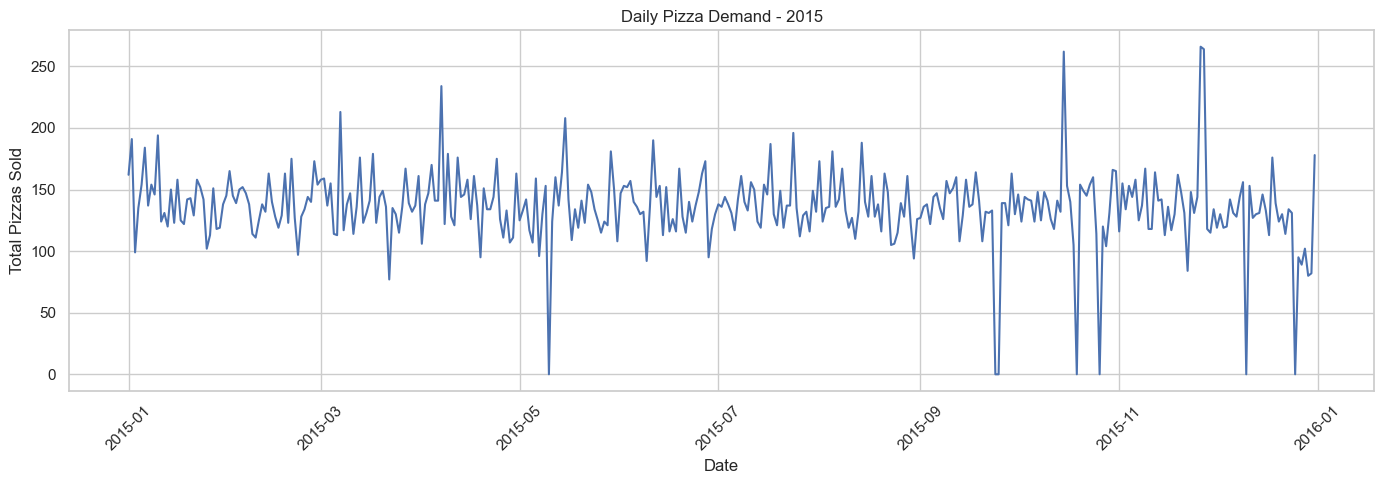

In [43]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_demand.index,
    daily_demand["total_pizzas"]
)

plt.title("Daily Pizza Demand - 2015")
plt.xlabel("Date")
plt.ylabel("Total Pizzas Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Daily demand fluctuates throughout 2015, but the visualisation does not show a clear continuous increase or decrease across the year. Most days remain within a relatively similar range, with some days showing considerably higher demand.

The values of zero correspond to the seven dates previously added as zero-sales days. The higher sales values are retained because the available data do not provide evidence that they are errors.

Together with the weekday and monthly results, this analysis shows that calendar-related demand patterns should be considered when preparing the forecasting variables.

## 6.4 Recipe Structure for Preparation and Ordering

The Proof of Concept will use predicted pizza demand to calculate the quantity of ingredients required for preparation and ordering. Before using the recipe data for these calculations, the recipe structure is examined in more detail.

This step checks how many ingredients are associated with each pizza and how ingredient quantities vary across pizza sizes. It also identifies the ingredients shared across multiple pizzas, which will later need to be combined when calculating total ingredient requirements.

In [44]:
recipe_structure = (
    ingredients_clean
    .groupby("pizza_name_id")
    .agg(
        ingredient_count=("pizza_ingredients", "nunique"),
        total_recipe_grams=("Items_Qty_In_Grams", "sum")
    )
    .sort_values("ingredient_count")
)

print("Pizza recipes:", len(recipe_structure))
print("Minimum ingredients in a recipe:", recipe_structure["ingredient_count"].min())
print("Maximum ingredients in a recipe:", recipe_structure["ingredient_count"].max())
print("Minimum total recipe weight (g):", recipe_structure["total_recipe_grams"].min())
print("Maximum total recipe weight (g):", recipe_structure["total_recipe_grams"].max())

display(recipe_structure)

Pizza recipes: 91
Minimum ingredients in a recipe: 2
Maximum ingredients in a recipe: 8
Minimum total recipe weight (g): 25.0
Maximum total recipe weight (g): 480.0


,ingredient_count,total_recipe_grams
pizza_name_id,,
pepperoni_s,2,30.0
pepperoni_m,2,60.0
pepperoni_l,2,90.0
hawaiian_s,3,40.0
pep_msh_pep_l,3,140.0
...,...,...
spinach_supr_l,8,275.0
southw_ckn_m,8,280.0
veggie_veg_l,8,275.0


The dataset contains 91 pizza recipes, with between 2 and 8 recorded ingredients per pizza ID. Total recorded ingredient quantities range from 25 g to 480 g per pizza.

The differences between pizza IDs indicate that ingredient requirements must be calculated using the specific `pizza_name_id` rather than only the pizza name. This is important because different pizza sizes can require different ingredient quantities.

Before using these recipes for preparation and ordering calculations, the ingredient composition and quantities across pizza sizes are examined in more detail.

### Recipe Quantities Across Pizza Sizes

Pizza recipes are compared across available sizes to check whether the recorded ingredient quantities change consistently between size variants.

This check is used to identify possible inconsistencies in the recipe data before the quantities are used to calculate preparation and ordering requirements.

In [45]:
recipe_size_check = (
    ingredients_clean[
        [
            "pizza_name",
            "pizza_name_id",
            "pizza_ingredients",
            "Items_Qty_In_Grams"
        ]
    ]
    .sort_values(
        ["pizza_name", "pizza_ingredients", "pizza_name_id"]
    )
)

display(recipe_size_check)

,pizza_name,pizza_name_id,pizza_ingredients,Items_Qty_In_Grams
5,The Barbecue Chicken Pizza,bbq_ckn_l,Barbecue Sauce,15.0
11,The Barbecue Chicken Pizza,bbq_ckn_m,Barbecue Sauce,10.0
17,The Barbecue Chicken Pizza,bbq_ckn_s,Barbecue Sauce,5.0
0,The Barbecue Chicken Pizza,bbq_ckn_l,Barbecued Chicken,40.0
6,The Barbecue Chicken Pizza,bbq_ckn_m,Barbecued Chicken,30.0
...,...,...,...,...
503,The Vegetables + Vegetables Pizza,veggie_veg_m,Tomatoes,20.0
511,The Vegetables + Vegetables Pizza,veggie_veg_s,Tomatoes,10.0
499,The Vegetables + Vegetables Pizza,veggie_veg_l,Zucchini,30.0
507,The Vegetables + Vegetables Pizza,veggie_veg_m,Zucchini,20.0


The recipe records show that ingredient quantities generally vary between pizza sizes. For example, some ingredients increase from the small to medium and large versions of the same pizza.

Because the dataset does not define a required proportional relationship between sizes, a fixed ratio is not assumed. Instead, the size variants are checked for differences in ingredient composition and quantity that may require further review before the recipes are used for preparation and ordering calculations.

In [46]:
pizza_sizes = (
    sales_clean[["pizza_name_id", "pizza_size"]]
    .drop_duplicates()
)

recipe_with_size = ingredients_clean.merge(
    pizza_sizes,
    on="pizza_name_id",
    how="left",
    validate="many_to_one"
)

print("Recipe rows:", len(recipe_with_size))
print("Missing pizza sizes:", recipe_with_size["pizza_size"].isna().sum())
print("Pizza IDs:", recipe_with_size["pizza_name_id"].nunique())

Recipe rows: 518
Missing pizza sizes: 0
Pizza IDs: 91


All 518 recipe records were successfully matched with their pizza size. No recipe records were lost or duplicated, and all 91 pizza IDs remain represented.

The recipe quantities can now be compared across the available pizza sizes.

In [47]:
recipe_pivot = (
    recipe_with_size
    .pivot_table(
        index=["pizza_name", "pizza_ingredients"],
        columns="pizza_size",
        values="Items_Qty_In_Grams",
        aggfunc="first"
    )
)

available_sizes = [
    size for size in ["S", "M", "L"]
    if size in recipe_pivot.columns
]

print("Pizza-ingredient combinations:", len(recipe_pivot))
print("Available size columns:", available_sizes)

display(recipe_pivot[available_sizes])

Pizza-ingredient combinations: 181
Available size columns: ['S', 'M', 'L']


pizza_size                                              S     M     L
pizza_name                        pizza_ingredients                  
The Barbecue Chicken Pizza        Barbecue Sauce      5.0  10.0  15.0
                                  Barbecued Chicken  20.0  30.0  40.0
                                  Green Peppers      20.0  15.0  20.0
                                  Red Onions         20.0  40.0  60.0
                                  Red Peppers         5.0  10.0  15.0
...                                                   ...   ...   ...
The Vegetables + Vegetables Pizza Red Onions         20.0  40.0  60.0
                                  Red Peppers         5.0  10.0  15.0
                                  Spinach            15.0  30.0  45.0
                                  Tomatoes           10.0  20.0  30.0
                                  Zucchini           10.0  20.0  30.0

[181 rows x 3 columns]

The comparison shows that many ingredient quantities increase across pizza sizes, but this pattern is not consistent for every ingredient. For example, the Barbecue Chicken Pizza records 20 g of Green Peppers for size S, 15 g for M and 20 g for L.

These differences are not changed because the source data do not provide enough information to determine whether they are errors or intentional recipe quantities. The next check identifies how frequently this type of pattern occurs before the recipe data are used for preparation and ordering calculations.

In [48]:
complete_size_recipes = recipe_pivot.dropna(
    subset=["S", "M", "L"]
).copy()

non_increasing_quantities = complete_size_recipes[
    ~(
        (complete_size_recipes["S"] <= complete_size_recipes["M"]) &
        (complete_size_recipes["M"] <= complete_size_recipes["L"])
    )
]

print(
    "Pizza-ingredient combinations with S, M and L:",
    len(complete_size_recipes)
)

print(
    "Combinations not following S <= M <= L:",
    len(non_increasing_quantities)
)

display(non_increasing_quantities)

Pizza-ingredient combinations with S, M and L: 160
Combinations not following S <= M <= L: 3


,pizza_size,L,M,S,XL,XXL
pizza_name,pizza_ingredients,,,,,
The Barbecue Chicken Pizza,Green Peppers,20.0,15.0,20.0,NaN,NaN
"The Pepperoni, Mushroom, and Peppers Pizza",Green Peppers,20.0,15.0,20.0,NaN,NaN
The Vegetables + Vegetables Pizza,Green Peppers,20.0,15.0,20.0,NaN,NaN


Of the 160 pizza–ingredient combinations available in S, M and L sizes, only three do not follow the pattern S ≤ M ≤ L. All three cases involve Green Peppers and use the same quantities: 20 g for S, 15 g for M and 20 g for L.

These values are retained because the source data do not provide evidence that they are incorrect. Changing them would require assumptions about the original recipes.

The dataset also contains XL and XXL pizza sizes for some products. For this reason, future preparation and ordering calculations will use the specific `pizza_name_id` and its recorded ingredient quantities rather than assuming that all pizzas use only S, M and L sizes.

### Ingredients Shared Across Pizza Recipes

The same ingredient can be used in several pizza recipes. For preparation and ordering calculations, the quantities required by different pizzas must therefore be combined to calculate the total requirement for each ingredient.

In [49]:
ingredient_usage = (
    ingredients_clean
    .groupby("pizza_ingredients")
    .agg(
        pizza_ids=("pizza_name_id", "nunique")
    )
    .sort_values("pizza_ids", ascending=False)
)

print("Unique ingredients:", len(ingredient_usage))
print(
    "Ingredients used by more than one pizza ID:",
    (ingredient_usage["pizza_ids"] > 1).sum()
)

display(ingredient_usage)

Unique ingredients: 64
Ingredients used by more than one pizza ID: 53


,pizza_ids
pizza_ingredients,
Garlic,57
Tomatoes,56
Red Onions,41
Red Peppers,30
Spinach,24
...,...
Prosciutto,1
Romano Cheese,1
Provolone Cheese,1


The recipe dataset contains 64 unique ingredients, and 53 are used by more than one pizza ID. Some ingredients, such as Garlic and Tomatoes, are shared across many pizza recipes.

The relationship between each `pizza_name_id` and its ingredients must be preserved so that ingredient requirements can be calculated for an individual pizza when needed. For example, the system should be able to calculate the ingredients required for the predicted number of Hawaiian pizzas for a specific day.


### Validation of Pizza-to-Ingredient Calculation

Before using predicted demand for preparation and ordering, the recipe data are tested with a known pizza quantity.

This check confirms that the system can take a specific pizza ID and quantity and convert it into the corresponding ingredient requirements while keeping the calculation linked to that pizza.

In [50]:
test_pizza_id = "hawaiian_l"
test_quantity = 10

test_recipe = ingredients_clean[
    ingredients_clean["pizza_name_id"] == test_pizza_id
].copy()

test_recipe["required_grams"] = (
    test_recipe["Items_Qty_In_Grams"] * test_quantity
)

print("Pizza ID:", test_pizza_id)
print("Test quantity:", test_quantity)
print("Recipe ingredients:", len(test_recipe))

display(
    test_recipe[
        [
            "pizza_ingredients",
            "Items_Qty_In_Grams",
            "required_grams"
        ]
    ]
)

Pizza ID: hawaiian_l
Test quantity: 10
Recipe ingredients: 3


,pizza_ingredients,Items_Qty_In_Grams,required_grams
149,Sliced Ham,45.0,450.0
150,Pineapple,45.0,450.0
151,Mozzarella Cheese,30.0,300.0


The test successfully converted a quantity of 10 `hawaiian_l` pizzas into the corresponding ingredient requirements. Based on the recorded recipe, this requires 450 g of Sliced Ham, 450 g of Pineapple and 300 g of Mozzarella Cheese.

This confirms that the recipe structure can convert a quantity for a specific pizza ID into its ingredient requirements. The same calculation can later use predicted quantities and can be applied to an individual pizza or combined with other pizza predictions when a complete preparation or ordering list is required.

## 6.5 Historical Ingredient Demand Analysis

Before simulating inventory, the historical daily usage of each ingredient is calculated from the cleaned sales and recipe data.

For each pizza sold, the quantity sold is multiplied by the quantity of each ingredient required by its recipe. Ingredient usage is then aggregated by date. This ensures that when the same ingredient is used in different pizzas, its total daily usage represents the combined requirement across all pizzas sold.

This analysis will be used to examine the historical distribution of ingredient demand before defining the simulated inventory target.

In [51]:
ingredient_sales = sales_clean[
    ["order_date", "pizza_name_id", "quantity"]
].merge(
    ingredients_clean[
        ["pizza_name_id", "pizza_ingredients", "Items_Qty_In_Grams"]
    ],
    on="pizza_name_id",
    how="left",
    validate="many_to_many"
)

ingredient_sales["used_grams"] = (
    ingredient_sales["quantity"]
    * ingredient_sales["Items_Qty_In_Grams"]
)

daily_ingredient_usage = (
    ingredient_sales
    .groupby(["order_date", "pizza_ingredients"])["used_grams"]
    .sum()
    .reset_index()
)

print("Sales rows:", len(sales_clean))
print("Unmatched recipe quantities:", ingredient_sales["Items_Qty_In_Grams"].isna().sum())
print("Ingredients represented:", daily_ingredient_usage["pizza_ingredients"].nunique())
print("Total ingredient usage (g):", daily_ingredient_usage["used_grams"].sum())

display(daily_ingredient_usage.head(10))

Sales rows: 48620
Unmatched recipe quantities: 0
Ingredients represented: 64
Total ingredient usage (g): 9090870.0


,order_date,pizza_ingredients,used_grams
0,2015-01-01,?duja Salami,40.0
1,2015-01-01,Alfredo Sauce,25.0
2,2015-01-01,Anchovies,55.0
3,2015-01-01,Artichokes,320.0
4,2015-01-01,Arugula,45.0
5,2015-01-01,Asiago Cheese,180.0
6,2015-01-01,Bacon,1670.0
7,2015-01-01,Barbecue Sauce,135.0
8,2015-01-01,Barbecued Chicken,380.0
9,2015-01-01,Beef Chuck Roast,350.0


### Complete Daily Ingredient Demand Structure

The historical ingredient usage currently contains records only for dates when an ingredient was used. To analyse ingredient demand correctly, days with no usage must also be represented.

A complete structure is created for all 365 dates and all 64 ingredients. When an ingredient was not used on a particular date, its daily usage is recorded as zero. This preserves the total historical usage while ensuring that each ingredient has a complete daily demand history.

In [52]:
all_dates = pd.date_range(
    start=sales_clean["order_date"].min(),
    end=sales_clean["order_date"].max(),
    freq="D"
)

all_ingredients = ingredients_clean["pizza_ingredients"].drop_duplicates()

complete_index = pd.MultiIndex.from_product(
    [all_dates, all_ingredients],
    names=["order_date", "pizza_ingredients"]
)

daily_ingredient_usage_complete = (
    daily_ingredient_usage
    .set_index(["order_date", "pizza_ingredients"])
    .reindex(complete_index, fill_value=0)
    .reset_index()
)

print("Rows:", len(daily_ingredient_usage_complete))
print("Dates:", daily_ingredient_usage_complete["order_date"].nunique())
print("Ingredients:", daily_ingredient_usage_complete["pizza_ingredients"].nunique())
print("Missing values:", daily_ingredient_usage_complete["used_grams"].isna().sum())
print("Zero-usage records:", (daily_ingredient_usage_complete["used_grams"] == 0).sum())
print("Total ingredient usage (g):", daily_ingredient_usage_complete["used_grams"].sum())

display(daily_ingredient_usage_complete.head(10))

Rows: 23360
Dates: 365
Ingredients: 64
Missing values: 0
Zero-usage records: 1225
Total ingredient usage (g): 9090870.0


,order_date,pizza_ingredients,used_grams
0,2015-01-01,Barbecued Chicken,380.0
1,2015-01-01,Red Peppers,745.0
2,2015-01-01,Green Peppers,375.0
3,2015-01-01,Tomatoes,2270.0
4,2015-01-01,Red Onions,3260.0
5,2015-01-01,Barbecue Sauce,135.0
6,2015-01-01,Bacon,1670.0
7,2015-01-01,Pepperoni,1410.0
8,2015-01-01,Italian Sausage,50.0
9,2015-01-01,Chorizo Sausage,250.0


### Ingredient Demand Statistics

Daily ingredient demand is analysed before defining the inventory target. Because the complete daily structure includes both usage and zero-usage days, the statistics represent the full 365-day period.

The mean and median are calculated to describe typical daily usage, while the 75th, 90th and 95th percentiles are included to examine higher-demand levels. The maximum is retained for comparison but is not assumed to represent normal demand.

These measures will be compared before selecting the rule used to define the simulated inventory target.

In [53]:
ingredient_demand_stats = (
    daily_ingredient_usage_complete
    .groupby("pizza_ingredients")["used_grams"]
    .agg(
        mean="mean",
        median="median",
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        maximum="max"
    )
    .round(1)
    .sort_values("mean", ascending=False)
)

display(ingredient_demand_stats)

,mean,median,p75,p90,p95,maximum
pizza_ingredients,,,,,,
Chicken,2662.5,2650.0,3150.0,3650.0,4000.0,5350.0
Red Onions,2366.6,2380.0,2680.0,2980.0,3216.0,4900.0
Capocollo,2115.2,2100.0,2550.0,2900.0,3150.0,4900.0
Tomatoes,1628.3,1630.0,1820.0,2036.0,2216.0,3240.0
Bacon,1375.1,1340.0,1640.0,1988.0,2266.0,3390.0
...,...,...,...,...,...,...
Arugula,40.1,40.0,55.0,70.0,80.0,130.0
Friggitello Peppers,28.1,25.0,40.0,50.0,65.0,105.0
Caramelized Onions,20.1,15.0,30.0,45.0,60.0,75.0


### Inventory Target Definition

The maximum historical daily usage is selected as the inventory target for each ingredient. This provides a simple and reproducible rule based directly on the observed ingredient demand.

Using the maximum rather than the mean or median provides additional capacity for days with higher demand without introducing an arbitrary percentage. The target represents the highest daily quantity of each ingredient required during the historical period.

This is a simulation rule for the Proof of Concept and does not represent actual inventory levels or an optimal inventory policy for the restaurant.

In [54]:
ingredient_targets = (
    ingredient_demand_stats[["maximum"]]
    .rename(columns={"maximum": "target_grams"})
    .reset_index()
)

print("Ingredients with targets:", len(ingredient_targets))
print("Missing targets:", ingredient_targets["target_grams"].isna().sum())
print("Targets <= 0:", (ingredient_targets["target_grams"] <= 0).sum())

display(ingredient_targets)

Ingredients with targets: 64
Missing targets: 0
Targets <= 0: 0


,pizza_ingredients,target_grams
0,Chicken,5350.0
1,Red Onions,4900.0
2,Capocollo,4900.0
3,Tomatoes,3240.0
4,Bacon,3390.0
...,...,...
59,Arugula,130.0
60,Friggitello Peppers,105.0
61,Caramelized Onions,75.0
62,Pears,50.0


### Simulated End-of-Day Inventory

The inventory dataset is simulated because the original dataset does not contain historical stock records.

For each ingredient, the inventory target is defined as its maximum historical daily usage. The simulation assumes that this target quantity is available at the beginning of each day. The quantity used according to the recorded pizza sales is then subtracted to estimate the remaining stock at the end of that day.

Therefore:

**Simulated end-of-day stock = inventory target − daily ingredient usage**

This produces a daily inventory value for each ingredient while keeping the simulated stock directly related to the historical sales and recipe data. The resulting values represent simulated end-of-day inventory and should not be interpreted as actual historical stock records.

In [55]:
simulated_inventory = (
    daily_ingredient_usage_complete
    .merge(
        ingredient_targets,
        on="pizza_ingredients",
        how="left",
        validate="many_to_one"
    )
)

simulated_inventory["stock_grams"] = (
    simulated_inventory["target_grams"]
    - simulated_inventory["used_grams"]
)

inventory_database = (
    simulated_inventory[
        ["order_date", "pizza_ingredients", "stock_grams"]
    ]
    .rename(columns={"pizza_ingredients": "ingredient"})
    .sort_values(["order_date", "ingredient"])
    .reset_index(drop=True)
)

print("Rows:", len(inventory_database))
print("Dates:", inventory_database["order_date"].nunique())
print("Ingredients:", inventory_database["ingredient"].nunique())
print("Missing stock values:", inventory_database["stock_grams"].isna().sum())
print("Negative stock values:", (inventory_database["stock_grams"] < 0).sum())
print("Zero stock values:", (inventory_database["stock_grams"] == 0).sum())

display(inventory_database.head(10))

Rows: 23360
Dates: 365
Ingredients: 64
Missing stock values: 0
Negative stock values: 0
Zero stock values: 119


,order_date,ingredient,stock_grams
0,2015-01-01,?duja Salami,380.0
1,2015-01-01,Alfredo Sauce,115.0
2,2015-01-01,Anchovies,245.0
3,2015-01-01,Artichokes,545.0
4,2015-01-01,Arugula,85.0
5,2015-01-01,Asiago Cheese,310.0
6,2015-01-01,Bacon,1720.0
7,2015-01-01,Barbecue Sauce,40.0
8,2015-01-01,Barbecued Chicken,120.0
9,2015-01-01,Beef Chuck Roast,870.0


In [56]:
check_ingredients = ["Pineapple", "Mozzarella Cheese", "Chicken"]

inventory_check = (
    simulated_inventory[
        simulated_inventory["pizza_ingredients"].isin(check_ingredients)
    ][
        ["order_date", "pizza_ingredients", "target_grams", "used_grams", "stock_grams"]
    ]
    .sort_values(["pizza_ingredients", "order_date"])
)

for ingredient in check_ingredients:
    print(f"\n{ingredient}")
    display(
        inventory_check[
            inventory_check["pizza_ingredients"] == ingredient
        ].head(10)
    )


Pineapple


,order_date,pizza_ingredients,target_grams,used_grams,stock_grams
40,2015-01-01,Pineapple,1110.0,435.0,675.0
104,2015-01-02,Pineapple,1110.0,495.0,615.0
168,2015-01-03,Pineapple,1110.0,270.0,840.0
232,2015-01-04,Pineapple,1110.0,315.0,795.0
296,2015-01-05,Pineapple,1110.0,570.0,540.0
360,2015-01-06,Pineapple,1110.0,375.0,735.0
424,2015-01-07,Pineapple,1110.0,435.0,675.0
488,2015-01-08,Pineapple,1110.0,360.0,750.0
552,2015-01-09,Pineapple,1110.0,465.0,645.0
616,2015-01-10,Pineapple,1110.0,615.0,495.0



Mozzarella Cheese


,order_date,pizza_ingredients,target_grams,used_grams,stock_grams
29,2015-01-01,Mozzarella Cheese,1230.0,620.0,610.0
93,2015-01-02,Mozzarella Cheese,1230.0,710.0,520.0
157,2015-01-03,Mozzarella Cheese,1230.0,490.0,740.0
221,2015-01-04,Mozzarella Cheese,1230.0,830.0,400.0
285,2015-01-05,Mozzarella Cheese,1230.0,730.0,500.0
349,2015-01-06,Mozzarella Cheese,1230.0,670.0,560.0
413,2015-01-07,Mozzarella Cheese,1230.0,720.0,510.0
477,2015-01-08,Mozzarella Cheese,1230.0,580.0,650.0
541,2015-01-09,Mozzarella Cheese,1230.0,530.0,700.0
605,2015-01-10,Mozzarella Cheese,1230.0,760.0,470.0



Chicken


,order_date,pizza_ingredients,target_grams,used_grams,stock_grams
19,2015-01-01,Chicken,5350.0,3050.0,2300.0
83,2015-01-02,Chicken,5350.0,4300.0,1050.0
147,2015-01-03,Chicken,5350.0,2200.0,3150.0
211,2015-01-04,Chicken,5350.0,2450.0,2900.0
275,2015-01-05,Chicken,5350.0,4100.0,1250.0
339,2015-01-06,Chicken,5350.0,3050.0,2300.0
403,2015-01-07,Chicken,5350.0,2200.0,3150.0
467,2015-01-08,Chicken,5350.0,2250.0,3100.0
531,2015-01-09,Chicken,5350.0,2250.0,3100.0
595,2015-01-10,Chicken,5350.0,2800.0,2550.0


The validation confirms that the simulated inventory follows the defined rule consistently. For each ingredient and date, the recorded daily usage is subtracted from its historical maximum daily usage to estimate the remaining end-of-day stock.

The examples for Pineapple, Mozzarella Cheese and Chicken show that the simulated stock changes according to historical ingredient demand and that the calculation produces no negative values. The simulated inventory can therefore be used as an inventory input for the Proof of Concept.


### 6.6 Exporting the simulated inventory

The simulated inventory is ready. I will export it to Excel so it can be used by the PoC without running the inventory calculations again.


In [57]:

inventory_database["ingredient"] = inventory_database["ingredient"].replace(
    "?duja Salami", "Nduja Salami"
)

print(
    inventory_database[
        inventory_database["ingredient"].str.contains("Salami", case=False)
    ]["ingredient"].unique()
)


['Nduja Salami' 'Calabrese Salami' 'Coarse Sicilian Salami' 'Genoa Salami'
 'Soppressata Salami']


In [58]:

inventory_database.to_excel(
    "6.Simulated_Inventory.xlsx",
    index=False
)

print("Inventory exported successfully.")
print("Rows:", len(inventory_database))
print("Ingredients:", inventory_database["ingredient"].nunique())


Inventory exported successfully.
Rows: 23360
Ingredients: 64


## 6.7 Simulated Inventory for 2016

The 2016 inventory is generated using the simulated inventory from the corresponding calendar dates in 2015. A fixed 7% increase is applied to each ingredient's stock quantity.

The original 2015 inventory remains unchanged. The resulting dataset provides simulated ingredient availability for testing the preparation and ordering functions of the Proof of Concept.

In [59]:
inventory_2016 = inventory_database.copy()

inventory_2016["order_date"] = (
    pd.to_datetime(inventory_2016["order_date"])
    + pd.DateOffset(years=1)
)

inventory_2016["stock_grams"] = (
    inventory_2016["stock_grams"] * 1.07
)

print("Rows:", len(inventory_2016))
print("Dates:", inventory_2016["order_date"].nunique())
print("Ingredients:", inventory_2016["ingredient"].nunique())
print("Missing values:", inventory_2016.isna().sum().sum())
print("Negative stock:", (inventory_2016["stock_grams"] < 0).sum())
print("Zero stock:", (inventory_2016["stock_grams"] == 0).sum())

display(inventory_2016.head(10))

Rows: 23360
Dates: 365
Ingredients: 64
Missing values: 0
Negative stock: 0
Zero stock: 119


,order_date,ingredient,stock_grams
0,2016-01-01,Nduja Salami,406.60
1,2016-01-01,Alfredo Sauce,123.05
2,2016-01-01,Anchovies,262.15
3,2016-01-01,Artichokes,583.15
4,2016-01-01,Arugula,90.95
5,2016-01-01,Asiago Cheese,331.70
6,2016-01-01,Bacon,1840.40
7,2016-01-01,Barbecue Sauce,42.80
8,2016-01-01,Barbecued Chicken,128.40
9,2016-01-01,Beef Chuck Roast,930.90


### 6.7.1 Inventory Validation

The simulated inventory is checked for mathematical consistency, daily stock availability, and duplicate records before exporting the 2016 dataset.

In [60]:
# Compare the 2016 stock against the 2015 reference.
expected_stock = inventory_database["stock_grams"] * 1.07

print(
    "Correct 7% calculation:",
    np.allclose(inventory_2016["stock_grams"], expected_stock)
)

print(
    "Duplicate date-ingredient records:",
    inventory_2016.duplicated(
        ["order_date", "ingredient"]
    ).sum()
)

daily_stock = inventory_2016.groupby(
    "order_date"
)["stock_grams"].sum()

print("Days with total stock = 0:", (daily_stock == 0).sum())
print("Minimum daily stock (grams):", daily_stock.min())
print("Maximum daily stock (grams):", daily_stock.max())

Correct 7% calculation: True
Duplicate date-ingredient records: 0
Days with total stock = 0: 0
Minimum daily stock (grams): 12545.75
Maximum daily stock (grams): 64799.200000000004


### 6.7.2 Exporting the 2016 Simulated Inventory

After validation, the simulated inventory for 2016 is exported to a separate Excel file. The original 2015 inventory remains unchanged. This dataset will be used by the Proof of Concept to calculate ingredient ordering recommendations.

In [61]:
from pathlib import Path

output_file_2016 = Path("7.Simulated_Inventory_2016.xlsx")

inventory_2016.to_excel(
    output_file_2016,
    index=False
)

print("File created:", output_file_2016.resolve())

File created: C:\Users\DELL\Desktop\Whitecliffe 2025-2026\IT9115 -  Project\1. Master Thesis – AI Commercial Kitchens\3. App (Proof of Concept)\7.Simulated_Inventory_2016.xlsx
